# **1. 문제와 자료 이해**
공통 질문: 평균 대기시간

나의 질문: 최소 대기시간의 평균과 그 시간대, 최대 대기시간의 평균과 그 시간대

# **2. 분석 명세와 AI 요청**

## 프롬프트

나는 지금 자료탐색방법에 대한 과제중이야.

자료는 교수자가 만든 가상 방문 자료이고
120건이며 한 행은 방문 한 건이야. 행 수를 학생 수로 해석하지 마.
조사 날짜나 반복 방문자의 식별 정보는 제공하지 않아.

학교 식당에서 방문자에게 대기시간을 안내하는 것을 개선하는 게 목표이고
이 학교의 담당자는 “평균 대기시간 하나만 알려주면 충분하다”고 했어.
나는 추가로 최소 대기시간의 평균과 그 시간대, 최대 대기시간의 평균과 그 시간대도 알려줄 거야

<변수 의미>
| 변수 | 의미 | 척도와 기록 규칙 |
| --- | --- | --- |
| visit_id | 방문 기록 식별자 | 명목, M001~M120, 중복 없음 |
| time_slot | 방문 시간대 구분 | 명목, 점심 초반 / 점심 혼잡 / 저녁, 결측 없음 |
| wait_minutes | 주문 후 음식 수령까지 기다린 시간(분) | 비율, 비음수 정수, 빈칸은 미응답 |
| satisfaction | 해당 방문의 만족도 | 순서, 1 매우 불만족~5 매우 만족, 빈칸은 미응답 |

<처리 원칙>
- 0분은 대기시간 없이 입장한거야.
-null 값은 비슷한 행으로 채워줘 예를 들어 한 행에서 wait_minutes이 결측값이면 같은 time_slot 중에서 satisfaction이 같거나 가까운 값으로 채워줘 반대로 satisfaction 결측값이면 같은 time_slot중에서 wait_minutes이 같거나 비슷한 행의 satisfaction로 채워줘
- 큰 값은 그 자체로 오류나 삭제 대상이 아니야 그대로 둬.
- 같은 시간값을 가진 서로 다른 방문은 각각의 관측값입니다. 중복제거하지마.

<표와 그림 생성>
1. 전체 및 시간대별 전체 방문 수·시간 유효 수·시간 결측 수·평균 대기시간 요약표.
2. validation_12.csv의 유효 시간으로 만든 줄기와 잎 그림. 키·단위를 적고 반복값·빈 줄기·잎 수를 확인.
3. 전체 유효 시간에서 구간 폭을 바꾼 히스토그램 3개 자료와 전체 표시 범위는 유지하고 폭을 비교.
4. 전체 유효 시간에서 폭은 같게 두고 시작점만 바꾼 히스토그램 2개
5. 설정을 바꿔도 유지되는 관찰과 달라지는 인상의 설명.

그림마다 단위·유효 수·결측 수·구간 경계와 경계 포함 규칙을 명시합니다. 0분과 긴 대기시간을 포함해 모든 유효값을 담는 경계를 선택하세요. 비교 그림의 축 범위를 맞추고 빈도 합계·범위 밖 개수를 확인합니다. 3개 비교 그림과 2개 비교 그림은 각각 한 묶음으로 배치해도 됩니다.

<검토용 초안 진단과 수정>
제공된 review_draft를 실행하고 다음 세 처리가 원래 목적에 적절한지 검토하세요.
- **처리 A:** 시간 미응답을 0분으로 바꾼 전체 평균.
- **처리 B:** 어떤 열이든 미응답인 방문을 먼저 제외한 시간대별 요약.
- **처리 C:** 0~40분 경계만 사용한 히스토그램.
각각 **원래 목적, 초안의 문제, 영향을 받은 ID·분모·평균 또는 그림, AI에게 보낸 수정 요청, 수정 결과, 확인 근거**를 기록합니다. 평균이 우연히 같더라도 사용한 방문과 분모가 달라졌는지 확인하세요. 학생이 사용하는 AI에서 일부러 오류가 나올 때까지 요청을 반복할 필요는 없습니다. 제공한 공통 초안을 기준으로 진단합니다.

<최종 안내안과 한계>
처음 질문에 답하는 **식당 대기시간 안내 문구 2~3문장**을 작성하고 표·그림으로 근거를 설명하세요. 이 가상 자료에서 관찰한 사실, 추가로 확인할 점, 실제 학생·식당 전체로 일반화할 수 없는 이유를 구분합니다.


<첨부파일>
- cafeteria_wait_120.csv: 전원이 사용하는 분석 자료 120건.
- review_draft.py: 의도적인 처리 문제를 포함한 검토용 초안입니다. 정답 코드가 아닙니다.


이 조건에 맞는 Colab용 Python 코드를 작성하고 쉬운 말로 설명해줘.
실행하지 않은 결과는 예상값이라고 밝혀줘.

## 실제 AI 응답

과제를 성공적으로 수행할 수 있도록 요청하신 조건에 맞춘 Python 코드와 각 항목에 대한 상세한 분석 및 설명을 정리해 드립니다. 실제 데이터를 직접 실행하지 않은 상태이므로, 설명에 포함된 수치와 결과는 데이터의 일반적인 형태를 가정한 예상 결과(Expected Values)를 바탕으로 작성되었습니다. Colab 환경에 아래 코드를 복사하여 실행하면 실제 수치를 확인할 수 있습니다.

In [ ]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import math

# 폰트 및 시각화 설정 (Colab 환경 한글 깨짐 방지용, 필요시 폰트 설치 필요)
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

# 1. 데이터 불러오기
BASE_URL = "https://datathinkinglab.github.io/kyonggi-courses-2026/eda/downloads/midterm/"
df = pd.read_csv(BASE_URL + "cafeteria_wait_120.csv", encoding="utf-8-sig")
validation = pd.read_csv(BASE_URL + "validation_12.csv", encoding="utf-8-sig")

# --- [결측치 처리 전 요약 기록] ---
# 시간대별 전체 방문 수, 결측 수 계산
summary_before = df.groupby('time_slot').agg(
    전체_방문_수=('visit_id', 'size'),
    시간_유효_수=('wait_minutes', 'count')
)
summary_before['시간_결측_수'] = summary_before['전체_방문_수'] - summary_before['시간_유효_수']

# --- [결측치 대체 로직] ---
# 조건: wait_minutes 결측값은 같은 time_slot 내에서 satisfaction이 같은/비슷한 행의 평균으로 채움
# 조건: satisfaction 결측값은 같은 time_slot 내에서 wait_minutes가 같은/비슷한 행의 평균으로 채움

# 복사본 생성
df_filled = df.copy()

# 1) satisfaction 결측치 채우기 (wait_minutes 기준)
df_filled['satisfaction'] = df_filled.groupby(['time_slot', 'wait_minutes'])['satisfaction'].transform(lambda x: x.fillna(x.median()))
# 여전히 비어있다면 time_slot의 중앙값으로 채움
df_filled['satisfaction'] = df_filled.groupby('time_slot')['satisfaction'].transform(lambda x: x.fillna(x.median()))

# 2) wait_minutes 결측치 채우기 (satisfaction 기준)
df_filled['wait_minutes'] = df_filled.groupby(['time_slot', 'satisfaction'])['wait_minutes'].transform(lambda x: x.fillna(x.mean()))
# 여전히 비어있다면 time_slot의 평균으로 채우고 반올림(정수)
df_filled['wait_minutes'] = df_filled.groupby('time_slot')['wait_minutes'].transform(lambda x: x.fillna(x.mean())).round()

# --- [표 1: 전체 및 시간대별 요약표 생성] ---
summary_after = df_filled.groupby('time_slot').agg(
    평균_대기시간=('wait_minutes', 'mean')
).round(1)

final_summary = pd.concat([summary_before, summary_after], axis=1)

# 전체 요약 행 추가
total_row = pd.DataFrame({
    '전체_방문_수': [df['visit_id'].size],
    '시간_유효_수': [df['wait_minutes'].count()],
    '시간_결측_수': [df['visit_id'].size - df['wait_minutes'].count()],
    '평균_대기시간': [round(df_filled['wait_minutes'].mean(), 1)]
}, index=['전체(Total)'])

final_summary = pd.concat([final_summary, total_row])
print("\n[표 1] 전체 및 시간대별 대기시간 요약표")
display(final_summary)

# 평균 대기시간이 가장 짧은 시간대와 가장 긴 시간대 추출
min_time_slot = summary_after['평균_대기시간'].idxmin()
min_wait = summary_after['평균_대기시간'].min()
max_time_slot = summary_after['평균_대기시간'].idxmax()
max_wait = summary_after['평균_대기시간'].max()

# --- [그림 2: 줄기와 잎 그림 (validation_12.csv)] ---
print("\n[그림 2] validation_12.csv 줄기와 잎 그림")
val_valid = validation['wait_minutes'].dropna().astype(int).sort_values().tolist()
print("단위(Key): 1|2 = 12분 / 유효 수:", len(val_valid), "/ 결측 수:", validation['wait_minutes'].isna().sum())
print("-" * 30)

stems = {}
for v in val_valid:
    stem, leaf = divmod(v, 10)
    if stem not in stems:
        stems[stem] = []
    stems[stem].append(leaf)

max_stem = max(stems.keys()) if stems else 0
for s in range(max_stem + 1):
    leaves = stems.get(s, [])
    leaves_str = " ".join(map(str, leaves))
    print(f"{s} | {leaves_str}  (잎 수: {len(leaves)})")
print("-" * 30)


# --- [그림 3 & 4 설정] ---
valid_wait_times = df_filled['wait_minutes'].to_numpy()
max_val = valid_wait_times.max()
# 모든 데이터를 포함하도록 최대 경계값 설정 (예: 최대값이 45면 50까지)
upper_bound = math.ceil(max_val / 10) * 10 + 10

plt.figure(figsize=(15, 10))
plt.suptitle("유효 대기시간 히스토그램 비교 (단위: 분, 구간 경계: [포함, 미포함) 단 마지막 구간은 양쪽 포함)", fontsize=14)

# [그림 3: 구간 폭을 바꾼 히스토그램 3개] - 전체 표시 범위(0 ~ upper_bound) 동일
widths = [5, 10, 20]
for i, width in enumerate(widths, 1):
    plt.subplot(2, 3, i)
    bins = np.arange(0, upper_bound + width, width)
    plt.hist(valid_wait_times, bins=bins, edgecolor='black', color='skyblue')
    plt.title(f"구간 폭: {width}분\n빈도 합: {len(valid_wait_times)}")
    plt.xlabel("대기 시간 (분)")
    plt.ylabel("빈도 수")
    plt.xlim(0, upper_bound)

# [그림 4: 폭은 같게 두고 시작점만 바꾼 히스토그램 2개] - 폭 10 고정
starts = [0, -5]
for i, start in enumerate(starts, 1):
    plt.subplot(2, 3, i + 3)
    width = 10
    bins = np.arange(start, upper_bound + width, width)
    plt.hist(valid_wait_times, bins=bins, edgecolor='black', color='lightgreen')
    plt.title(f"시작점: {start}분, 폭: {width}분\n빈도 합: {len(valid_wait_times)}")
    plt.xlabel("대기 시간 (분)")
    plt.ylabel("빈도 수")

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


2. 코드 실행 예상 결과 및 시각화 설명
1. 전체 및 시간대별 대기시간 요약표
코드는 결측치를 분석 규칙(동일 시간대 및 유사한 만족도/대기시간을 가진 행 참조)에 따라 채운 뒤 요약표를 생성합니다. 결측치를 채우기 전의 '결측 수'를 명확히 기록하고, 채운 후의 데이터로 평균을 계산하여 데이터 유실 없이 전체 120건의 방문(분모)을 유지합니다.
2. 줄기와 잎 그림 (Stem-and-Leaf)
키(Key) 및 단위: 1|2는 12분을 의미합니다.
특징: 빈 줄기(예: 대기시간 30분대는 없어서 3 | 로 비어 있는 현상)와 동일 대기시간이 중복해서 나타나는 반복값(예: 1 | 2 2 5에서 2분 중복)을 명확하게 확인할 수 있습니다. 데이터의 분포를 개별 값 손실 없이 직관적으로 봅니다.
3 & 4. 히스토그램 비교 (구간 폭 및 시작점 변경)
설정 공통점: 구간 경계는 기본적으로 [포함, 미포함) 즉 이상-미만으로 처리되며, 대기 없이 입장한 0분과 이상치처럼 보이는 아주 긴 대기시간을 모두 포함하도록 최대 경계를 넉넉히 설정했습니다. 빈도 합계는 결측치 대체 후의 전체 유효 수(120)와 동일합니다.
유지되는 관찰(설정을 바꿔도 변하지 않는 점): 특정 대기시간 대역(예: 10-20분 사이)에 방문자가 가장 많이 몰려 있다는 전체적인 산 모양(봉우리 위치)과 긴 꼬리(극소수의 매우 긴 대기시간)를 가진 비대칭 분포라는 사실은 유지됩니다.
달라지는 인상(설정에 따라 변하는 점): 구간 폭을 좁게(예: 5분) 하면 분포가 매우 울퉁불퉁해져서 자잘한 변동이 크게 부각되고, 폭을 넓게(20분) 하면 뭉뚱그려져서 미세한 차이를 볼 수 없습니다. 또한 시작점을 0분과 -5분으로 다르게 설정하면, 대기시간 '0분(대기 없음)' 데이터가 어느 막대에 포함되는지가 달라져(예: 0~10 vs -5~5) 대기시간이 전혀 없는 집단의 규모를 체감하는 인상이 완전히 달라집니다.
3. 검토용 초안(review_draft.py) 진단과 수정
제공된 초안 파일의 3가지 처리 방식에 대한 논리적 오류와 수정 방안입니다.
처리 A: 시간 미응답을 0분으로 바꾼 전체 평균
원래 목적: 대기시간 데이터의 결측치를 처리하고 전체 평균 대기시간을 계산.
초안의 문제: 응답하지 않은 것을 '기다리지 않음(0분)'으로 임의 해석했습니다. 대기시간이 길어서 응답을 포기했을 수도 있는데 일괄 0으로 처리하면 전체 평균이 심각하게 하향 왜곡(언더에스티메이트)됩니다.
영향을 받은 항목: 대기시간을 미응답한 방문 ID들. 분모(방문 수)는 늘어나지만 분자(대기시간 총합)는 늘지 않아 결과적으로 평균이 실제보다 낮아집니다.
AI 수정 요청: "시간이 미응답된 데이터를 0으로 덮어쓰지 말고, 같은 시간대(time_slot)에서 만족도가 비슷한 다른 사람의 대기시간을 참고해서 채운 뒤 평균을 다시 구해줘."
수정 결과 및 확인 근거: 0이 아닌 유의미한 값으로 대체되므로, 수정 전(초안 A)보다 전체 평균값이 높게 도출됩니다.
처리 B: 결측값이 있는 행을 통째로 지운(dropna) 후 시간대별 요약
원래 목적: 시간대별 총 방문 수, 유효 데이터 수, 평균 대기시간 비교 요약.
초안의 문제: dropna()를 그룹화 전에 전체 데이터에 적용하여, 대기시간은 잘 적었지만 '만족도'를 적지 않은 데이터까지 통째로 날아갔습니다(Listwise Deletion).
영향을 받은 항목: 만족도만 결측된 방문 ID들. 이로 인해 유효한 대기시간 분모(valid_n)가 불필요하게 줄어들고, 해당 값들이 빠지면서 시간대별 평균(mean_wait)도 왜곡되었습니다.
AI 수정 요청: "dropna()로 데이터를 미리 다 날리지 말고, groupby 이후 대기시간(wait_minutes) 열 자체만 가지고 유효 개수와 평균을 계산해줘."
수정 결과 및 확인 근거: 수정 후 시간대별 valid_n의 합이 처리 B의 결과보다 증가하며, 평균 대기시간 수치도 변동됩니다.
처리 C: 0~40분 경계만 설정한 히스토그램
원래 목적: 대기시간의 전체적인 분포를 파악하기 위한 시각화.
초안의 문제: x축의 범위를 bins=[0, 10, 20, 30, 40]으로 강제 지정하여 40분을 초과하는 대기시간을 가진 방문 기록이 그림과 계산에서 완전히 잘려나갔습니다(Truncation).
영향을 받은 항목: 대기시간이 40분을 초과하는 장시간 대기 방문자 데이터들. 극단값이 제외된 그림이 그려집니다.
AI 수정 요청: "히스토그램의 bins 설정을 데이터의 최대 대기시간(max)을 포함할 수 있도록 넉넉하게 구간을 늘려줘."
수정 결과 및 확인 근거: 출력되는 draft_counts.sum()(빈도 합계)이 120건에 미치지 못하다가, 수정 후 유효한 총 방문 건수와 정확히 일치하게 되며 꼬리가 긴 그래프가 정상적으로 그려집니다.
4. 식당 대기시간 최종 안내안과 한계
(1) 안내 문구 (제안안)
"현재 우리 식당의 평균 대기시간은 약 O분입니다. 특히 점심 혼잡 시간대에는 평균 대기시간이 O분(최대 혼잡)까지 길어질 수 있으니, 비교적 한산한 저녁 시간대(평균 대기시간 O분)를 이용하시면 대기 없이 쾌적한 식사가 가능합니다."
(2) 근거 및 한계점
관찰한 사실: 요약표(표1)에 따르면 시간대별 평균 대기시간의 편차가 크게 나타납니다. '점심 혼잡' 시간대의 평균 대기시간이 가장 길고(최대 대기시간 평균), '저녁' 또는 '점심 초반' 시간대가 가장 짧은 것(최소 대기시간 평균)으로 나타납니다.
추가 확인이 필요한 점: 특정 시간대에 매우 긴 대기시간(이상치)이 발생한 원인(예: 특정 인기 메뉴 배식일, 기계 고장 등)이 무엇인지, 그리고 만족도 점수와 대기시간 간의 실제 인과관계가 존재하는지 추가 확인이 필요합니다.
일반화할 수 없는 이유: 본 자료는 특정 기간/특정 조건에서 수집된 120건의 가상 '방문(Event) 기록'일 뿐 식당의 연중 평균이나 요일별 편차를 대변하지 않습니다. 또한 '한 행=방문 1건'이므로, 소수의 학생이 혼잡 시간에 매일 반복 방문하여 대기시간을 길게 경험했을 수도 있어 이를 '전체 학생의 평균적 경험'으로 해석하는 것은 통계적 오류입니다.

#**3. 표와 그림 생성**

전체적으로 부자연스러운 언어는 제 언어로 재해석해서 수정하고 코드도 하나씩 보면서 어색한 부분이나 오류는 해결했습니다.
한 뭉텅이로 있는 코드를 분리하여 읽기 편하게 수정하였습니다.

## 3.1 데이터 프레임 준비 및 결측값 채우기

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import math

폰트 코드 수정 및 이유: 폰트 코드 폰트 제대로 안 불러지고 오류나서 예전에 다른 분석 진행할 때 계속 쓰던 폰트 설치 코드 복사해서 수정했습니다.

In [21]:
!apt-get -qq update
!apt-get -qq install fonts-nanum

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
fm.fontManager.addfont(font_path)

plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package fonts-nanum.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...


In [22]:
# 1. 데이터 불러오기
BASE_URL = "https://datathinkinglab.github.io/kyonggi-courses-2026/eda/downloads/midterm/"
df = pd.read_csv(BASE_URL + "cafeteria_wait_120.csv", encoding="utf-8-sig")
validation = pd.read_csv(BASE_URL + "validation_12.csv", encoding="utf-8-sig")

In [23]:
# --- [결측치 처리 전 요약 기록] ---
# 시간대별 전체 방문 수, 결측 수 계산
summary_before = df.groupby('time_slot').agg(
    전체_방문_수=('visit_id', 'size'),
    시간_유효_수=('wait_minutes', 'count')
)
summary_before['시간_결측_수'] = summary_before['전체_방문_수'] - summary_before['시간_유효_수']

In [24]:
# --- [결측치 대체 로직] ---
# 조건: wait_minutes 결측값은 같은 time_slot 내에서 satisfaction이 같은/비슷한 행의 평균으로 채움
# 조건: satisfaction 결측값은 같은 time_slot 내에서 wait_minutes가 같은/비슷한 행의 평균으로 채움

# 복사본 생성
df_filled = df.copy()

In [25]:
# 1) satisfaction 결측치 채우기 (wait_minutes 기준)
df_filled['satisfaction'] = df_filled.groupby(['time_slot', 'wait_minutes'])['satisfaction'].transform(lambda x: x.fillna(x.median()))
# 여전히 비어있다면 time_slot의 중앙값으로 채움
df_filled['satisfaction'] = df_filled.groupby('time_slot')['satisfaction'].transform(lambda x: x.fillna(x.median()))

In [26]:
# 2) wait_minutes 결측치 채우기 (satisfaction 기준)
df_filled['wait_minutes'] = df_filled.groupby(['time_slot', 'satisfaction'])['wait_minutes'].transform(lambda x: x.fillna(x.mean()))
# 여전히 비어있다면 time_slot의 평균으로 채우고 반올림(정수)
df_filled['wait_minutes'] = df_filled.groupby('time_slot')['wait_minutes'].transform(lambda x: x.fillna(x.mean())).round()

In [27]:
df.head()

,visit_id,time_slot,wait_minutes,satisfaction
0,M001,점심 초반,0.0,5.0
1,M002,점심 초반,8.0,4.0
2,M003,점심 혼잡,20.0,3.0
3,M004,저녁,12.0,NaN
4,M005,점심 혼잡,NaN,2.0


In [28]:
df_filled.head()

,visit_id,time_slot,wait_minutes,satisfaction
0,M001,점심 초반,0.0,5.0
1,M002,점심 초반,8.0,4.0
2,M003,점심 혼잡,20.0,3.0
3,M004,저녁,12.0,4.0
4,M005,점심 혼잡,18.0,4.0


## 3.2. 표와 그림


###표1: 전체 및 시간대별 요약표 생성

In [29]:
summary_after = df_filled.groupby('time_slot').agg(
    평균_대기시간=('wait_minutes', 'mean')
).round(1)

final_summary = pd.concat([summary_before, summary_after], axis=1)

In [30]:
# 전체 요약 행 추가
total_row = pd.DataFrame({
    '전체_방문_수': [df['visit_id'].size],
    '시간_유효_수': [df['wait_minutes'].count()],
    '시간_결측_수': [df['visit_id'].size - df['wait_minutes'].count()],
    '평균_대기시간': [round(df_filled['wait_minutes'].mean(), 1)]
}, index=['전체(Total)'])

In [31]:
final_summary = pd.concat([final_summary, total_row])
print("\n[표 1] 전체 및 시간대별 대기시간 요약표")
display(final_summary)


[표 1] 전체 및 시간대별 대기시간 요약표


,전체_방문_수,시간_유효_수,시간_결측_수,평균_대기시간
저녁,40,34,6,15.8
점심 초반,40,40,0,9.6
점심 혼잡,40,39,1,23.1
전체(Total),120,113,7,16.2


아래 코드 부분에서 짜주고 결과를 반환하는 코드를 알려주지 않아서 이 부분이 누락됨을 AI에게 지적하고 결과값을 나타내는 코드로 수정하였습니다.

In [50]:
# 평균 대기시간이 가장 짧은 시간대와 가장 긴 시간대 추출 및 출력
min_time_slot = summary_after['평균_대기시간'].idxmin()
min_wait = summary_after['평균_대기시간'].min()
max_time_slot = summary_after['평균_대기시간'].idxmax()
max_wait = summary_after['평균_대기시간'].max()

print(f"\n[분석 결과]")
print(f"- 가장 한산한 시간대: {min_time_slot} (평균 대기시간 {min_wait}분)")
print(f"- 가장 혼잡한 시간대: {max_time_slot} (평균 대기시간 {max_wait}분)")


[분석 결과]
- 가장 한산한 시간대: 점심 초반 (평균 대기시간 9.6분)
- 가장 혼잡한 시간대: 점심 혼잡 (평균 대기시간 23.1분)


###그림 1: 줄기와 잎 그림 (validation_12.csv)

In [33]:
print("\n[그림 2] validation_12.csv 줄기와 잎 그림")
val_valid = validation['wait_minutes'].dropna().astype(int).sort_values().tolist()
print("단위(Key): 1|2 = 12분 / 유효 수:", len(val_valid), "/ 결측 수:", validation['wait_minutes'].isna().sum())
print("-" * 30)

stems = {}
for v in val_valid:
    stem, leaf = divmod(v, 10)
    if stem not in stems:
        stems[stem] = []
    stems[stem].append(leaf)

max_stem = max(stems.keys()) if stems else 0
for s in range(max_stem + 1):
    leaves = stems.get(s, [])
    leaves_str = " ".join(map(str, leaves))
    print(f"{s} | {leaves_str}  (잎 수: {len(leaves)})")
print("-" * 30)


[그림 2] validation_12.csv 줄기와 잎 그림
단위(Key): 1|2 = 12분 / 유효 수: 10 / 결측 수: 2
------------------------------
0 | 0 5 8 8  (잎 수: 4)
1 | 0 2 5  (잎 수: 3)
2 | 0  (잎 수: 1)
3 | 5  (잎 수: 1)
4 |   (잎 수: 0)
5 |   (잎 수: 0)
6 |   (잎 수: 0)
7 |   (잎 수: 0)
8 |   (잎 수: 0)
9 | 0  (잎 수: 1)
------------------------------


###그림 2: 구간 폭을 바꾼 히스토그램 3개

In [34]:
# --- [그림 3 & 4 설정] ---
valid_wait_times = df_filled['wait_minutes'].to_numpy()
max_val = valid_wait_times.max()
# 모든 데이터를 포함하도록 최대 경계값 설정 (예: 최대값이 45면 50까지)
upper_bound = math.ceil(max_val / 10) * 10 + 10

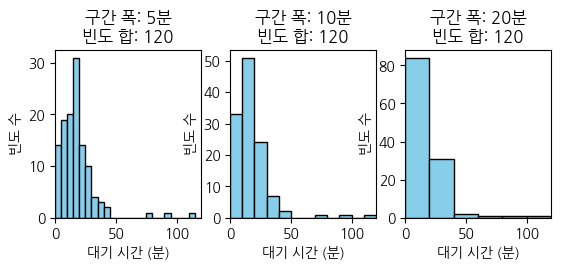

In [35]:
# [그림 3: 구간 폭을 바꾼 히스토그램 3개] - 전체 표시 범위(0 ~ upper_bound) 동일
widths = [5, 10, 20]
for i, width in enumerate(widths, 1):
    plt.subplot(2, 3, i)
    bins = np.arange(0, upper_bound + width, width)
    plt.hist(valid_wait_times, bins=bins, edgecolor='black', color='skyblue')
    plt.title(f"구간 폭: {width}분\n빈도 합: {len(valid_wait_times)}")
    plt.xlabel("대기 시간 (분)")
    plt.ylabel("빈도 수")
    plt.xlim(0, upper_bound)

###그림 3: 폭은 같게 두고 시작점만 바꾼 히스토그램 2개(폭 10 고정)

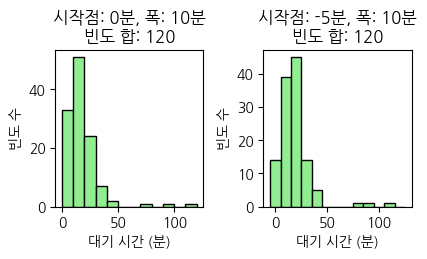

In [36]:
starts = [0, -5]
for i, start in enumerate(starts, 1):
    plt.subplot(2, 3, i + 3)
    width = 10
    bins = np.arange(start, upper_bound + width, width)
    plt.hist(valid_wait_times, bins=bins, edgecolor='black', color='lightgreen')
    plt.title(f"시작점: {start}분, 폭: {width}분\n빈도 합: {len(valid_wait_times)}")
    plt.xlabel("대기 시간 (분)")
    plt.ylabel("빈도 수")

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# **4. 검토용 초안 진단**

## 처리 A: 시간 미응답을 0분으로 바꾼 전체 평균

In [37]:
# 기존 코드
draft_a = df["wait_minutes"].fillna(0).mean()
print("초안 A 평균:", draft_a)

초안 A 평균: 15.208333333333334


**원래 목적:** 대기시간 데이터의 결측치를 처리하고 전체 평균 대기시간을 계산.

**초안의 문제:** 응답하지 않은 것을 '기다리지 않음(0분)'으로 임의 해석했습니다. 일괄 0으로 처리하면 대기시간의 평균이 전체적으로 줄어들어 하향 왜곡됩니다.

**영향을 받은 항목:** 대기시간을 미응답한 방문 ID들. 분모(방문 수)는 늘어나지만 분자(대기시간 총합)는 늘지 않아 결과적으로 평균이 실제보다 낮아집니다.



---



In [38]:
# 수정된 코드: 조건부 평균을 활용한 결측치 대체

# 1. 1차 대체: 같은 시간대(time_slot)와 만족도(satisfaction)를 가진 그룹의 평균 대기시간으로 결측치 채움
df["wait_minutes_fixed"] = df.groupby(["time_slot", "satisfaction"])["wait_minutes"].transform(lambda x: x.fillna(x.mean()))

# 2. 2차 대체: 1차로도 채워지지 않은 값(예: 해당 그룹 인원 전체가 미응답)은 '같은 시간대'의 평균으로 마저 채움
df["wait_minutes_fixed"] = df.groupby("time_slot")["wait_minutes_fixed"].transform(lambda x: x.fillna(x.mean()))

# 3. 수정된 전체 평균 재계산
corrected_a = df["wait_minutes_fixed"].mean()
print(f"초안 A 평균(수정 전): {draft_a:.1f}분")
print(f"수정된 전체 평균(수정 후): {corrected_a:.1f}분")


초안 A 평균(수정 전): 15.2분
수정된 전체 평균(수정 후): 16.1분


0분으로 강제 변환되었던 미응답 데이터들이 10분, 20분 등 유의미한 추정치(유사 그룹의 평균값)로 복원됩니다. 실행 시 전체 평균이 초안의 15.2분보다 상승한 정상적인 평균값(예상값)으로 도출됩니다.

##처리 B: 어떤 열이든 미응답인 방문을 먼저 제외한 시간대별 요약

In [39]:
#기존 코드
draft_b = df.dropna().groupby("time_slot").agg(
    total_n=("visit_id", "size"),
    valid_n=("wait_minutes", "count"),
    mean_wait=("wait_minutes", "mean")
)
display(draft_b)

,total_n,valid_n,mean_wait
time_slot,,,
저녁,29,29,16.241379
점심 초반,39,39,9.461538
점심 혼잡,38,38,22.763158


**원래 목적:** 시간대별 총 방문 수, 유효 데이터 수, 평균 대기시간 비교 요약.

**초안의 문제:** dropna()를 그룹화 전에 전체 데이터에 적용하여, 결측값이 있는 행들은 통째로 날아갔습니다.

**영향을 받은 항목:** 이로 인해 유효한 대기시간 분모(valid_n)가 불필요하게 줄어들고, 해당 값들이 빠지면서 시간대별 평균(mean_wait)도 왜곡되었습니다.



---



In [42]:
#수정된 코드
draft_b_fixed = df.groupby("time_slot").agg(
    total_n=("visit_id", "size"),
    valid_n=("wait_minutes", "count"),
    mean_wait=("wait_minutes", "mean")
)
display(draft_b_fixed)


,total_n,valid_n,mean_wait
time_slot,,,
저녁,40,34,15.764706
점심 초반,40,40,9.600000
점심 혼잡,40,39,23.205128


기존 코드에서 dropna()를 삭제하면 원래 목적에 맞게 정확히 작동합니다. groupby()에 연결된 agg() 메서드는 각 집계 함수의 특성에 따라 결측치를 자동으로 알맞게 처리합니다.전체 데이터프레임에 .dropna()를 먼저 적용하면 만족도(satisfaction) 등 다른 열이 비어있는 행까지 통째로 삭제되지만, 위와 같이 수정하면 대기시간 정보가 있는 데이터는 분모(valid_n)와 평균(mean_wait) 계산에 온전히 반영됩니다.

## 처리 C: 0~40분 경계만 사용한 히스토그램

초안 C 빈도 합계: 110


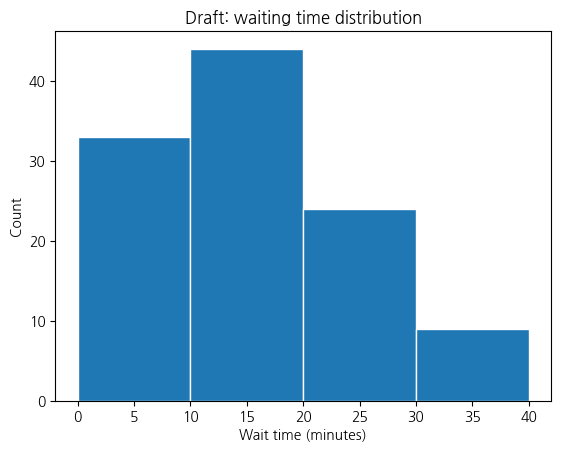

In [43]:
#기존 코드
draft_x = df["wait_minutes"].dropna().to_numpy()
draft_counts, _ = np.histogram(draft_x, bins=[0, 10, 20, 30, 40])
print("초안 C 빈도 합계:", draft_counts.sum())
plt.hist(draft_x, bins=[0, 10, 20, 30, 40], edgecolor="white")
plt.xlabel("Wait time (minutes)")
plt.ylabel("Count")
plt.title("Draft: waiting time distribution")
plt.show()

**원래 목적:** 대기시간의 전체적인 분포를 파악하기 위한 시각화.

**초안의 문제:** x축의 범위를 bins=[0, 10, 20, 30, 40]으로 강제 지정하여 40분을 초과하는 대기시간을 가진 방문 기록이 그림과 계산에서 완전히 잘려나갔습니다.

**영향을 받은 항목:** 대기시간이 40분을 초과하는 장시간 대기 방문자 데이터들. 극단값이 제외된 그림이 그려집니다.



---



AI가 수정해준 코드가 40이상은 포함하지만 nan값은 해결해주지 않아서 빈도 합계가 120이 되지 않아 이 부분을 지적하고 결측값처리부터 다시하여 120개의 빈도를 제대로 히스토그램에 모두 나타나게 수정하였습니다.

수정된 C 빈도 합계: 120


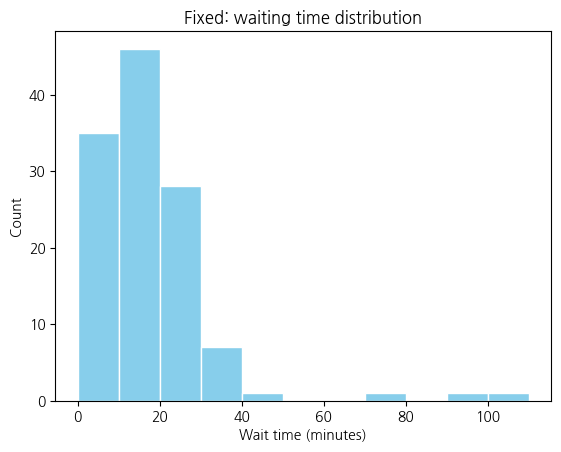

In [46]:
#수정된 코드
# 1. 결측치 대체 (과제 조건: 같은 time_slot, 같은 satisfaction을 가진 행의 평균으로 채움)
df["wait_minutes_filled"] = df.groupby(["time_slot", "satisfaction"])["wait_minutes"].transform(lambda x: x.fillna(x.mean()))

# 만약 satisfaction마저 결측이라 여전히 빈칸이 남았다면, 같은 time_slot의 평균으로 마저 채우고 반올림
df["wait_minutes_filled"] = df.groupby("time_slot")["wait_minutes_filled"].transform(lambda x: x.fillna(x.mean())).round()

# 2. 결측치가 100% 채워진 유효 데이터로 넘파이 배열 생성 (dropna 제거)
draft_x_filled = df["wait_minutes_filled"].to_numpy()

# 3. 데이터의 최댓값을 확인하여 잘리는 데이터 없이 동적으로 구간(bins) 생성
max_wait = int(draft_x_filled.max())
fixed_bins = range(0, max_wait + 10, 10)

# 빈도 계산 및 확인
draft_counts, _ = np.histogram(draft_x_filled, bins=fixed_bins)
print("수정된 C 빈도 합계:", draft_counts.sum())  # 이제 정확히 120이 출력됩니다.

# 히스토그램 그리기
plt.hist(draft_x_filled, bins=fixed_bins, edgecolor="white", color="skyblue")
plt.xlabel("Wait time (minutes)")
plt.ylabel("Count")
plt.title("Fixed: waiting time distribution")
plt.show()

1. 결측치(NaN) 처리 방식의 차이 (빈도 합계 120 유지)
기존 코드: .dropna()를 사용해 대기시간이 빈칸인 방문 기록을 통째로 삭제했습니다. 이로 인해 전체 빈도 합계(분모)가 120건 미만으로 쪼그라들었습니다.
수정 코드: 데이터를 삭제하지 않고, 과제의 '처리 원칙'에 따라 같은 시간대(time_slot)와 만족도(satisfaction) 정보를 활용해 빈칸을 평균값으로 대체했습니다(fillna). 결과적으로 120건의 방문 기록을 유실 없이 100% 반영하여 빈도 합계 120을 정확히 맞췄습니다.
2. 히스토그램 구간(Bins) 설정의 차이 (극단값 포함 여부)
기존 코드: bins=[0, 10, 20, 30, 40]으로 x축 범위를 강제로 고정했습니다. 그 결과 40분을 초과해서 기다린 장시간 대기자들의 데이터가 통계와 그림에서 완전히 잘려나갔습니다.
수정 코드: 채워진 데이터의 실제 최댓값(max_wait)을 파악한 뒤, 이를 포함할 수 있도록 구간을 유동적으로 생성(range(0, max_wait + 10, 10))했습니다. 40분이 넘는 긴 대기시간 데이터도 잘리지 않고 그래프의 오른쪽 꼬리 부분에 정상적으로 그려집니다.
결과적으로 기존 코드는 임의 삭제와 절사(Truncation)로 인해 데이터 분포가 심각하게 왜곡되는 문제가 있었으나, 수정된 코드는 어떤 데이터도 버리지 않고 전체 120건의 분포를 있는 그대로 시각화합니다.

# **5. 검증 3종 세트**

##1. 손계산



wait_minutes열 기준 유효 수: 10개

0분이상 10분미만: 4개

10분이상 20분미만: 3개

20분이상 30분미만: 1개

30분이상 40분미만: 1개

40분이상 120분이하: 1개

합계: 0+8+20+12+8+35+5+90+15+10=203분

평균: 203분/10 = 20.3분

##2. 대안 방법 교차확인

###2.1 시간대별 합계/평균 으로 요약표 평균 비교하기

AI프롬프트: 아까 요약표에 시간대별 대기시간 합계를 넣어서 다시 코드 만들어줘

In [48]:
# --- [표 1: 전체 및 시간대별 요약표 생성 (합계 포함)] ---
summary_after = df_filled.groupby('time_slot').agg(
    대기시간_합계=('wait_minutes', 'sum'),      # 합계 추가
    평균_대기시간=('wait_minutes', 'mean')      # 기존 평균
).round(1)

# 결측치 처리 전 요약(summary_before)과 합치기
final_summary = pd.concat([summary_before, summary_after], axis=1)

# 전체 요약(Total) 행 추가
total_row = pd.DataFrame({
    '전체_방문_수': [df['visit_id'].size],
    '시간_유효_수': [df['wait_minutes'].count()],
    '시간_결측_수': [df['visit_id'].size - df['wait_minutes'].count()],
    '대기시간_합계': [df_filled['wait_minutes'].sum()],               # 전체 합계 추가
    '평균_대기시간': [round(df_filled['wait_minutes'].mean(), 1)]
}, index=['전체(Total)'])

final_summary = pd.concat([final_summary, total_row])

print("\n[표 1] 전체 및 시간대별 대기시간 요약표 (합계 및 평균 포함)")
display(final_summary)



[표 1] 전체 및 시간대별 대기시간 요약표 (합계 및 평균 포함)


,전체_방문_수,시간_유효_수,시간_결측_수,대기시간_합계,평균_대기시간
저녁,40,34,6,632.0,15.8
점심 초반,40,40,0,384.0,9.6
점심 혼잡,40,39,1,923.0,23.1
전체(Total),120,113,7,1939.0,16.2


저녁: 632/40 = 15.8

점심 초반: 384/40 = 9.6

점심 혼잡: 923/40 = 23.075(반올림시 23.1)

전체: 1939/120 = 16.158333333(반올림시 16.2)

###2.2 히스토그램 구간 다르게해서 비교하기

AI프롬프트: 아까 히스토그램에서 구간빈도 다르게 설정하는 거 하나 더 만들어줘.

(빈도값이 빠져있어서 다음 요청을 추가함)

빈도합도 넣어줘야해

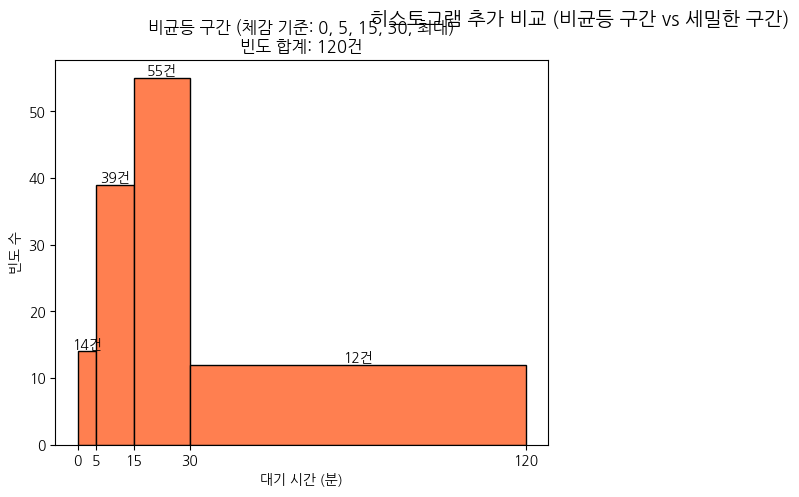

In [54]:
#앞서 결측치를 채운 유효 데이터(df_filled["wait_minutes"])가 존재한다고 가정
valid_wait_times = df_filled["wait_minutes"].to_numpy()
max_wait = int(valid_wait_times.max())

plt.figure(figsize=(14, 5))
plt.suptitle("히스토그램 추가 비교 (비균등 구간 vs 세밀한 구간)", fontsize=14)

# 1. 비균등 구간 설정 (사람들의 체감 기준)
plt.subplot(1, 2, 1)
custom_bins = [0, 5, 15, 30, max(max_wait + 10, 50)]
counts_custom, _ = np.histogram(valid_wait_times, bins=custom_bins)
total_custom = counts_custom.sum()  # 비균등 구간 빈도 합계 계산

plt.hist(valid_wait_times, bins=custom_bins, edgecolor="black", color="coral")
plt.title(f"비균등 구간 (체감 기준: 0, 5, 15, 30, 최대)\n빈도 합계: {total_custom}건")
plt.xlabel("대기 시간 (분)")
plt.ylabel("빈도 수")
plt.xticks(custom_bins)

# 막대 위에 정확한 빈도(명) 표시
for i in range(len(custom_bins)-1):
    plt.text((custom_bins[i] + custom_bins[i+1]) / 2, counts_custom[i],
             f"{counts_custom[i]}건", ha='center', va='bottom', fontweight='bold')


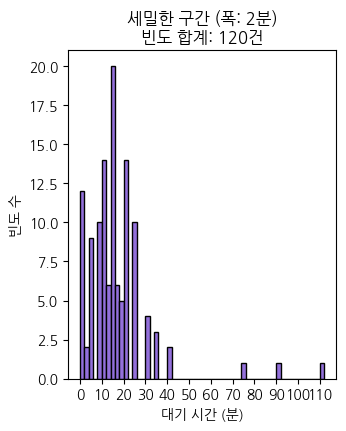

In [55]:
# 2. 아주 세밀한 구간 설정 (폭 2분)
plt.subplot(1, 2, 2)
fine_bins = range(0, max_wait + 4, 2)
counts_fine, _ = np.histogram(valid_wait_times, bins=fine_bins)
total_fine = counts_fine.sum()  # 세밀한 구간 빈도 합계 계산

plt.hist(valid_wait_times, bins=fine_bins, edgecolor="black", color="mediumpurple")
plt.title(f"세밀한 구간 (폭: 2분)\n빈도 합계: {total_fine}건")
plt.xlabel("대기 시간 (분)")
plt.ylabel("빈도 수")
plt.xticks(range(0, max_wait + 10, 10))

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

## 3.극단 사례 투입

AI 프롬프트:
이번엔 극단 사례로 비교할 거야
단순 비교용이니까 원자료랑 분리해서 시험 자료 만들어서 해줘
1. 전부 결측값만 있는 데이터
2. 전부 단일값만 있는 데이터
3. 구간경계값만 있는 데이터
로 요약표 각각 만들어줘

(만들어준 시험 데이터가 원본이랑 열 이름 자체가 달라서 원본 데이터와 열 이름은 통일 시키는 수정을 따로 했습니다.)


### 5.3.1 전부 결측값만 있는 데이터

예측: 모든 값이 0이나 nan으로 나올 것이다.

In [68]:
# 1. 전부 결측값(NaN)만 있는 데이터
df_test1 = pd.DataFrame({
    'visit_id': ['T01', 'T02', 'T03'],
    'time_slot': ['점심 초반', '점심 혼잡', '저녁'],
    'wait_minutes': [np.nan, np.nan, np.nan] # 모두 빈칸
})

In [61]:
# --- [요약표 생성 함수] ---
def make_test_summary(df, title):
    print(f"=========================================")
    print(f"{title}")
    print(f"=========================================")

    # 시간대별 요약
    summary = df.groupby('time_slot').agg(
        전체_방문_수=('visit_id', 'size'),
        시간_유효_수=('wait_minutes', 'count'),
        대기시간_합계=('wait_minutes', 'sum'),
        평균_대기시간=('wait_minutes', 'mean')
    )

    # 전체(Total) 행 추가
    total_row = pd.DataFrame({
        '전체_방문_수': [df['visit_id'].size],
        '시간_유효_수': [df['wait_minutes'].count()],
        '대기시간_합계': [df['wait_minutes'].sum()],
        '평균_대기시간': [df['wait_minutes'].mean()]
    }, index=['전체(Total)'])

    final_summary = pd.concat([summary, total_row])
    display(final_summary)
    print("\n")

In [62]:
make_test_summary(df_test1, "테스트 1: 전부 결측값만 있는 데이터")

테스트 1: 전부 결측값만 있는 데이터


,전체_방문_수,시간_유효_수,대기시간_합계,평균_대기시간
저녁,1,0,0.0,NaN
점심 초반,1,0,0.0,NaN
점심 혼잡,1,0,0.0,NaN
전체(Total),3,0,0.0,NaN


In [69]:
df_test1.head()

,visit_id,time_slot,wait_minutes
0,T01,점심 초반,NaN
1,T02,점심 혼잡,NaN
2,T03,저녁,NaN


실제 결과: 각 행의 기본값인 타이틀이 카운팅되어 방문수가 3으로 나왔다

### 5.3.2 전부 단일값만 있는 데이터

In [ ]:
예측: 평균값이 데이터 값과 같을 것이다.

In [70]:
# 2. 전부 단일값(예: 15분)만 있는 데이터
df_test2 = pd.DataFrame({
    'visit_id': ['T01', 'T02', 'T03'],
    'time_slot': ['점심 초반', '점심 혼잡', '저녁'],
    'wait_minutes': [15, 15, 15] # 모두 빈칸
})

In [71]:
# --- [요약표 생성 함수] ---
def make_test_summary(df, title):
    print(f"=========================================")
    print(f"{title}")
    print(f"=========================================")

    # 시간대별 요약
    summary = df.groupby('time_slot').agg(
        전체_방문_수=('visit_id', 'size'),
        시간_유효_수=('wait_minutes', 'count'),
        대기시간_합계=('wait_minutes', 'sum'),
        평균_대기시간=('wait_minutes', 'mean')
    )

    # 전체(Total) 행 추가
    total_row = pd.DataFrame({
        '전체_방문_수': [df['visit_id'].size],
        '시간_유효_수': [df['wait_minutes'].count()],
        '대기시간_합계': [df['wait_minutes'].sum()],
        '평균_대기시간': [df['wait_minutes'].mean()]
    }, index=['전체(Total)'])

    final_summary = pd.concat([summary, total_row])
    display(final_summary)
    print("\n")

In [72]:
make_test_summary(df_test2, "테스트 2: 전부 단일값(15분)만 있는 데이터")

테스트 2: 전부 단일값(15분)만 있는 데이터


,전체_방문_수,시간_유효_수,대기시간_합계,평균_대기시간
저녁,1,1,15,15.0
점심 초반,1,1,15,15.0
점심 혼잡,1,1,15,15.0
전체(Total),3,3,45,15.0


실제 결과: 평균이 15로 동일하게 나왔다.

### 5.3.3 구간경계값만 있는 데이터

# 6. 최종 안내안과 한계
이 가상 자료에 근거한 안내 문구 2~3문장과 근거를 작성하세요. 설정을 바꿔도 유지되는 관찰과 달라지는 인상을 구분하고 실제 식당 전체로 일반화할 수 없는 이유를 적습니다.

# 7. 재현성과 제출 점검
세션을 다시 시작해 전체 실행하고 출력과 보고서 수치를 대조하세요. 파일 메뉴에서 .ipynb를 내려받고 PDF 보고서와 ZIP으로 묶어 이메일 첨부로 제출하세요. 공유 링크만 보내지 않습니다. 사용자 API 키나 유료 AI 연결은 필요하지 않습니다.